In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import logging
from matplotlib.colors import LogNorm  # Necessary for the heatmap color scaling

# Plotting configuration
plt.rcdefaults()
plt.style.use('tableau-colorblind10')
%matplotlib widget

plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 12,
})

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')




In [2]:
# --- PATHS ---
base_path = "/home/STORAGE/MN5_resims/fiducial/hydro_output"
snap_num = "264"
snap_dir = f"snapdir_{snap_num}"
group_dir = f"groups_{snap_num}"

# --- USER SELECTION ---
isub = 0  # General Index: 0 is biggest, 1000 is smaller, etc.
box_width = 2 # Zoom window in Mpc/h

# --- STEP 1: LOCATE HALO IN GROUP FILES ---
print(f">>> Searching for Halo ID {isub} in Group Catalog...")

>>> Searching for Halo ID 0 in Group Catalog...


In [3]:
# First, we open file 0 just to get the total number of files, and the redshift
f0_path = os.path.join(base_path, group_dir, f"fof_subhalo_tab_{snap_num}.0.hdf5")
with h5py.File(f0_path, 'r') as f:
    n_group_files = f['Header'].attrs['NumFiles']
    redshift = f['Header'].attrs['Redshift']
    print(f"   Total Group Files to scan: {n_group_files}")
    print(f"   Redshift: {redshift}")

# Variables to track our position in the global list
halo_counter = 0            # How many halos we have passed
global_offset_counter = np.zeros(6, dtype=np.int64) # Cumulative particles (Gas, DM, Empty, Tracers, Stars, BH)
found_halo = False

# Halo properties container
target_halo = {}

# Iterate over ALL group files to calculate the correct global offset
for i in range(n_group_files):
    g_file = os.path.join(base_path, group_dir, f"fof_subhalo_tab_{snap_num}.{i}.hdf5")
    
    with h5py.File(g_file, 'r') as f:
        # Number of subhalos in THIS file
        n_subs_this_file = f['Header'].attrs['Nsubhalos_ThisFile']
        
        # Check if our target 'isub' is within this file's range
        if not found_halo and (halo_counter + n_subs_this_file > isub):
            print(f"   [HIT] Target Halo {isub} found in file: {g_file}")
            
            # The local index inside this specific file
            local_index = isub - halo_counter
            
            # Read properties for our target
            target_halo['Mass'] = f['Subhalo']['SubhaloMass'][local_index]
            target_halo['CM'] = f['Subhalo']['SubhaloCM'][local_index]
            target_halo['LenType'] = f['Subhalo']['SubhaloLenType'][local_index]
            
            # Now we calculate the exact offset for THIS specific halo.
            # 1. We already have 'global_offset_counter' which sums up all particles from FILES 0 to i-1.
            # 2. Now we add the particles from halos 0 to 'local_index' inside THIS file.
            
            # Read all lengths in this file to calculate local cumsum
            all_lens = f['Subhalo']['SubhaloLenType'][:] # Shape (N_subs, 6)
            
            # Sum all halos before our target in this file
            local_offset = np.sum(all_lens[:local_index, :], axis=0)
            
            # Final Global Offset = Offsets from prev files + Offsets from prev halos in this file
            target_halo['GlobalOffset'] = global_offset_counter + local_offset
            
            found_halo = True
            
        # Update counters for the next iteration (accumulate total particles processed so far)
        # We assume the file is valid and has SubhaloLenType. 
        # If Nsubhalos_ThisFile > 0, we sum up.
        if n_subs_this_file > 0:
            # Sum all particles in this file to add to the global tracker
            # Optimized: reading the dataset is fast, summing is fast.
            # If we already found the halo, we technically could stop IF we trust we don't need subsequent info.
            # But to be robust, usually we loop or just break if found (offsets are cumulative from start).
            if not found_halo:
                 # Only need to accumulate if we haven't reached the target file yet
                 # Reading the whole array might be heavy if file is huge, but it's the only safe way for offsets
                 lens = f['Subhalo']['SubhaloLenType'][:]
                 global_offset_counter += np.sum(lens, axis=0)
                 halo_counter += n_subs_this_file
            else:
                # We found it, no need to read more files
                break

if not found_halo:
    print("Error: Halo ID out of range.")
    sys.exit()

print("\n--- TARGET INFO ---")
print(f"Mass: {target_halo['Mass']:.2f} * 10^10 Msun/h")
print(f"Center: {target_halo['CM']}")
print(f"Lengths (Gas, DM, Stars): {target_halo['LenType'][0]}, {target_halo['LenType'][1]}, {target_halo['LenType'][4]}")
print(f"Global Offsets: {target_halo['GlobalOffset']}")

   Total Group Files to scan: 8
   Redshift: 4.440892098500626e-16
   [HIT] Target Halo 0 found in file: /home/STORAGE/MN5_resims/fiducial/hydro_output/groups_264/fof_subhalo_tab_264.0.hdf5

--- TARGET INFO ---
Mass: 74226.96 * 10^10 Msun/h
Center: [ 89.23169 319.92474 373.0667 ]
Lengths (Gas, DM, Stars): 4483558, 5698017, 185269
Global Offsets: [0 0 0 0 0 0]


In [4]:
# --- STEP 2: MAP SNAPSHOT FILES STRUCTURE ---
# We need to know which snapshot file contains the range of particles we need.
# Instead of loading everything, we scan headers to build a look-up table.

print("\n>>> Mapping Snapshot structure...")

# Get number of snapshot files from header of file 0
snap_f0 = os.path.join(base_path, snap_dir, f"snapshot_{snap_num}.0.hdf5")
with h5py.File(snap_f0, 'r') as f:
    n_snap_files = f['Header'].attrs['NumFilesPerSnapshot']

# This list will store tuples: (Start_Index, End_Index, File_Path) for each Particle Type
# structure: snap_map[PartType] = [ (start, end, filename), (start, end, filename)... ]
snap_map = {0: [], 1: [], 4: []} # 0=Gas, 1=DM, 4=Stars

# Counters for global position in snapshot
current_offset = np.zeros(6, dtype=np.int64)

for i in range(n_snap_files):
    s_file = os.path.join(base_path, snap_dir, f"snapshot_{snap_num}.{i}.hdf5")
    
    with h5py.File(s_file, 'r') as f:
        # NumPart_ThisFile gives array of counts [Gas, DM, Empty, Tracers, Stars, BH]
        n_part_this = f['Header'].attrs['NumPart_ThisFile'].astype(np.int64)
        
        # Map Gas (0), DM (1) and Stars (4)
        for ptype in [0, 1, 4]:
            count = n_part_this[ptype]
            start = current_offset[ptype]
            end = start + count
            
            # Store the range for this file
            snap_map[ptype].append( (start, end, s_file) )
            
            # Update global counter
            current_offset[ptype] += count

print(f"   Mapped {n_snap_files} snapshot files successfully.")


>>> Mapping Snapshot structure...
   Mapped 8 snapshot files successfully.


In [5]:
# --- STEP 3: SMART LOADER FUNCTION ---

def load_particle_chunk(ptype, start_idx, count, mapping_data):
    """
    Loads a specific range of particles [start_idx, start_idx + count]
    by finding which files they reside in.
    """
    if count == 0:
        return np.array([])
    
    end_idx = start_idx + count
    loaded_data = []
    
    # Iterate through our file map to find intersections
    # interval is (file_start, file_end, filename)
    for f_start, f_end, f_name in mapping_data[ptype]:
        
        # Check for intersection between Request [start, end] and File [f_start, f_end]
        # Logic: max of starts < min of ends
        req_start = max(start_idx, f_start)
        req_end = min(end_idx, f_end)
        
        if req_start < req_end:
            # We have an overlap! Calculate local indices relative to this file
            local_start = req_start - f_start
            local_end = req_end - f_start
            
            # print(f"   Reading {ptype} from {f_name}: local[{local_start}:{local_end}]")
            
            with h5py.File(f_name, 'r') as f:
                # Load only coordinates for now
                data = f[f'PartType{ptype}']['Coordinates'][local_start:local_end]
                loaded_data.append(data)
    
    if len(loaded_data) > 0:
        return np.concatenate(loaded_data)
    else:
        return np.array([])

# --- EXECUTE LOAD ---
print(f"\n>>> Extracting Particles for Halo {isub}...")

# Use indices from Target Halo info (Step 1)
# 0 = Gas
gas_coords = load_particle_chunk(0, target_halo['GlobalOffset'][0], target_halo['LenType'][0], snap_map)
print(f"   Gas Loaded: {gas_coords.shape[0]} particles")

# 1 = DM
dm_coords = load_particle_chunk(1, target_halo['GlobalOffset'][1], target_halo['LenType'][1], snap_map)
print(f"   DM Loaded: {dm_coords.shape[0]} particles")

# 4 = Stars
star_coords = load_particle_chunk(4, target_halo['GlobalOffset'][4], target_halo['LenType'][4], snap_map)
print(f"   Stars Loaded: {star_coords.shape[0]} particles")


>>> Extracting Particles for Halo 0...
   Gas Loaded: 4483558 particles
   DM Loaded: 5698017 particles
   Stars Loaded: 185269 particles


In [6]:
# Helper to plot density maps
def plot_halo_component(ax, coords, cm, name, cmap, nbins=200):
    if coords.shape[0] == 0:
        ax.text(0.5, 0.5, "No Data", ha='center')
        return

    # Center coordinates (Periodic Boundary Conditions omitted for simplicity here)
    # If the halo is on the edge of the box (0/500), simple subtraction looks weird.
    # But for isub=0 usually it's fine.
    dx = coords[:,0] - cm[0]
    dy = coords[:,1] - cm[1]
    
    # 2D Histogram with LogNorm
    h = ax.hist2d(dx, dy, bins=nbins, norm=LogNorm(), cmap=cmap, range=[[-box_width, box_width], [-box_width, box_width]])
    ax.set_title(f"{name}\nN={len(coords)}")
    ax.set_xlabel("dx [Mpc/h]")
    ax.set_ylabel("dy [Mpc/h]")
    ax.set_aspect('equal')
    
    # Add colorbar
    plt.colorbar(h[3], ax=ax, fraction=0.046, pad=0.04)


>>> Generating plots...


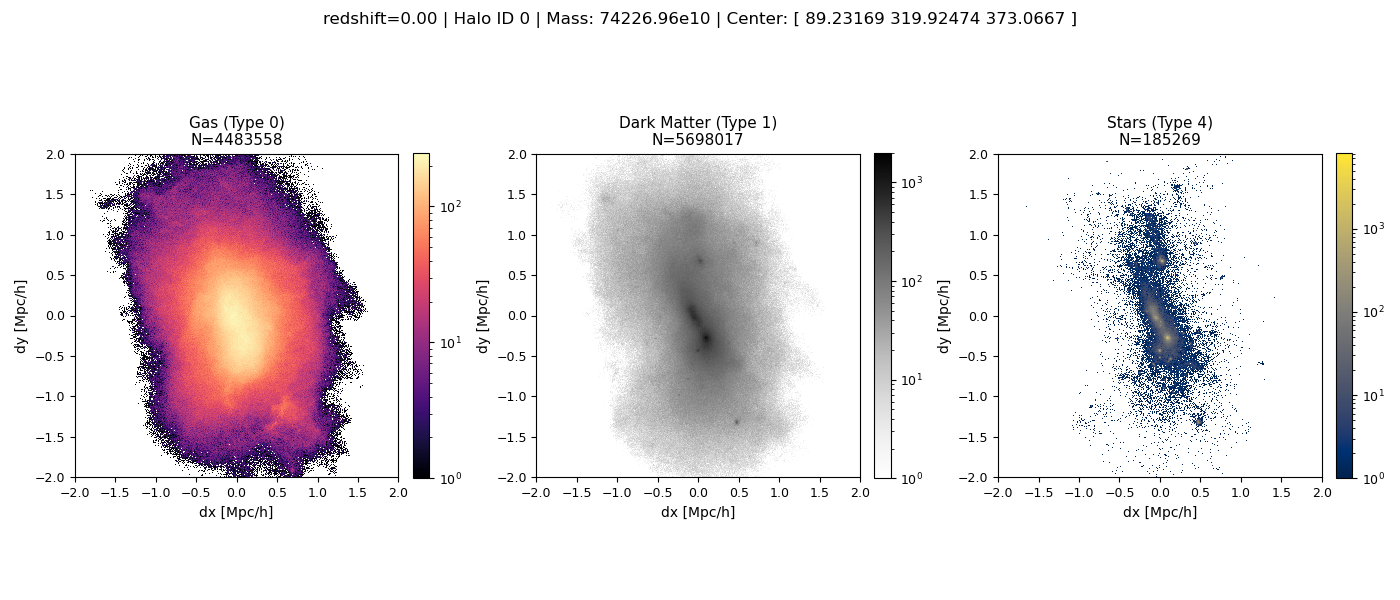

Done.


In [7]:
# Execute plots
# --- STEP 4: PLOTTING ---
print("\n>>> Generating plots...")

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
cm = target_halo['CM']

plot_halo_component(axes[0], gas_coords, cm, "Gas (Type 0)", "magma", 500)
plot_halo_component(axes[1], dm_coords, cm, "Dark Matter (Type 1)", "Greys", 500)
plot_halo_component(axes[2], star_coords, cm, "Stars (Type 4)", "cividis", 500)

plt.suptitle(f"redshift={redshift:.2f} | Halo ID {isub} | Mass: {target_halo['Mass']:.2f}e10 | Center: {cm}")
plt.tight_layout()
plt.show()
print("Done.")


>>> Generating plots...


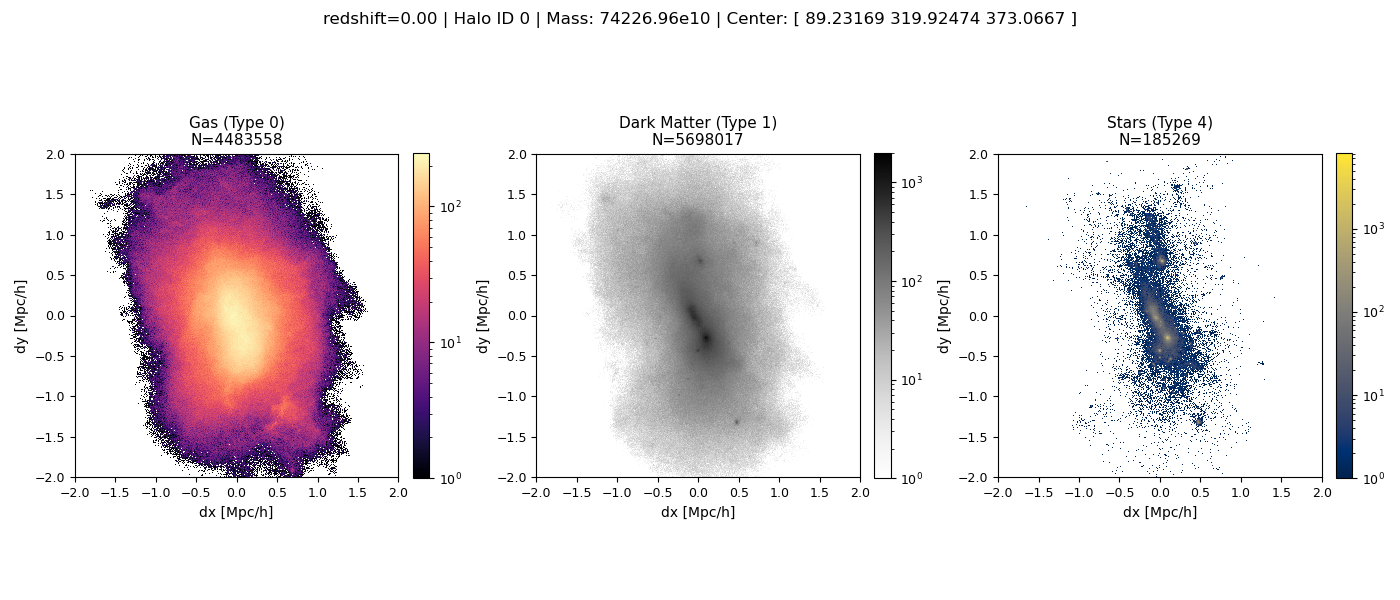

Done.


In [8]:
# Execute plots
# --- STEP 4: PLOTTING ---
print("\n>>> Generating plots...")

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
cm = target_halo['CM']

plot_halo_component(axes[0], gas_coords, cm, "Gas (Type 0)", "magma", 500)
plot_halo_component(axes[1], dm_coords, cm, "Dark Matter (Type 1)", "Greys", 500)
plot_halo_component(axes[2], star_coords, cm, "Stars (Type 4)", "cividis", 500)

plt.suptitle(f"redshift={redshift:.2f} | Halo ID {isub} | Mass: {target_halo['Mass']:.2f}e10 | Center: {cm}")
plt.tight_layout()
plt.show()
print("Done.")

# What about the redshifts?

In [9]:
import os
import h5py
import glob

# Base directory matching your terminal output
base_path = '/home/STORAGE/MN5_resims/fiducial/hydro_output'

# Find all snapdir folders and sort them
snapdirs = sorted(glob.glob(os.path.join(base_path, 'snapdir_*')))

print(f"{'Snapshot':<10} | {'Redshift (z)':<12} | {'Scale Factor (a)':<15}")
print("-" * 45)

for snapdir in snapdirs:
    # Extract the snapshot number (e.g., '094', '264') from the folder name
    snap_num_str = os.path.basename(snapdir).split('_')[-1]
    
    # Build the path to the first chunk of the snapshot
    snap_file = os.path.join(snapdir, f'snapshot_{snap_num_str}.0.hdf5')
    
    if os.path.exists(snap_file):
        with h5py.File(snap_file, 'r') as f:
            header = f['Header'].attrs
            
            # Extract scale factor (Time)
            a_scale = header.get('Time', -1.0)
            
            # Extract Redshift explicitly, or compute from scale factor if missing
            z_sim = header.get('Redshift', (1.0 / a_scale) - 1.0 if a_scale > 0 else -1.0)
            
            # Print formatted results
            print(f"{snap_num_str:<10} | z = {z_sim:<8.3f} | a = {a_scale:<10.3f}")
    else:
        print(f"{snap_num_str:<10} | [Error: File not found]")

Snapshot   | Redshift (z) | Scale Factor (a)
---------------------------------------------
094        | z = 2.978    | a = 0.251     
129        | z = 1.994    | a = 0.334     
151        | z = 1.504    | a = 0.399     
179        | z = 0.995    | a = 0.501     
199        | z = 0.696    | a = 0.590     
214        | z = 0.501    | a = 0.666     
232        | z = 0.297    | a = 0.771     
237        | z = 0.245    | a = 0.803     
264        | z = 0.000    | a = 1.000     
